# Homework 1 - Item 1
İpek Şençimen 

22302588

In [78]:
import numpy as np

Numpy is imported 

In [79]:
a=np.random.randint(1,1001,100)

It creates a NumPy array consisting of 100 random numbers selected from the range starting at 1 (inclusive) up to, but not including, 1001.

In [80]:
print(a)

[ 18 349 741 738 791 876 254 875 962 447 772 979 126 339  35 889 440 676
 385  88 510 129 378 395 576  83 888 423 729 696 910 785 471 815 776 808
 847 938 871 941 918 308 884 297 592 890   9 515 429 652 229 785 173 997
 637 602 157 869 355 607 539 449 500 135 111 388 896 900 963  25 924 490
  30 923 282 357 464 632 180 527 748 543 650 549 973 257 325 939 364 638
 737 700 116 121 186 664 518 658 550 312]


In [81]:
a.std()

np.float64(287.593152039474)

Computes the population standard deviation, where the denominator is N.

In [82]:
a.std(ddof=1)

np.float64(289.04199320926335)

Computes the sample standard deviation, where the denominator is (N-1).

In [83]:
mean=sum(a)/100

In [84]:
mean

np.float64(549.17)

Calculates the average of 100 numbers in an array.

In [85]:
est=np.sqrt(sum((a-mean)**2)/(np.size(a)-1))

In [86]:
est

np.float64(289.04199320926335)

Manually calculates the sample standard deviation, which is the same as std(ddof=1).

# Item 2


In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Modern NumPy random generator
rng = np.random.default_rng(seed=10)

# Generate 10,000 random numbers from two distributions
uniform_data = rng.random(10_000)                  # uniform on [0, 1)
normal_data = rng.normal(0, 1, size=10_000)        # normal with mean 0 and std 1

uniform_data = rng.random(size=(10000))                  # uniform on [0, 1)
normal_data = rng.normal(0, 1, size=(10000))  

print(uniform_data)
print(normal_data)

a_min=np.amin(a)
sort
max and min valuue
steps

In [88]:
def manual_bin_counts(data, bin_edges):
    """
    Count how many data points fall into each bin.

    Bins are left-closed and right-open:
        [lo, hi)

    The last bin is closed on both sides:
        [lo, hi]
    """
    counts = []

    for i in range(len(bin_edges) - 1):
        lo = bin_edges[i]
        hi = bin_edges[i + 1]

        if i == len(bin_edges) - 2:
            # Last bin includes the right edge
            mask = (data >= lo) & (data <= hi)
        else:
            # Other bins are [lo, hi)
            mask = (data >= lo) & (data < hi)

        counts.append(mask.sum())

    return np.array(counts)

In [89]:
# Equal-width bin edges
uniform_bins = np.linspace(0, 1, 11)       # 10 bins between 0 and 1
normal_bins = np.linspace(-4, 4, 17)       # 16 bins between -4 and 4

# Manual counts
uniform_counts = manual_bin_counts(uniform_data, uniform_bins)
normal_counts = manual_bin_counts(normal_data, normal_bins)

In [90]:
uniform_table = pd.DataFrame({
    "bin_left": uniform_bins[:-1],
    "bin_right": uniform_bins[1:],
    "count": uniform_counts
})

normal_table = pd.DataFrame({
    "bin_left": normal_bins[:-1],
    "bin_right": normal_bins[1:],
    "count": normal_counts
})

print("Uniform distribution bin counts:")
display(uniform_table)

print("Normal distribution bin counts:")
display(normal_table)

Uniform distribution bin counts:


,bin_left,bin_right,count
0,0.0,0.1,959
1,0.1,0.2,1002
2,0.2,0.3,990
3,0.3,0.4,1037
4,0.4,0.5,1003
5,0.5,0.6,1022
6,0.6,0.7,938
7,0.7,0.8,1035
8,0.8,0.9,1021
9,0.9,1.0,993


Normal distribution bin counts:


,bin_left,bin_right,count
0,-4.0,-3.5,3
1,-3.5,-3.0,12
2,-3.0,-2.5,55
3,-2.5,-2.0,184
4,-2.0,-1.5,456
5,-1.5,-1.0,913
6,-1.0,-0.5,1424
7,-0.5,0.0,1865
8,0.0,0.5,1951
9,0.5,1.0,1528


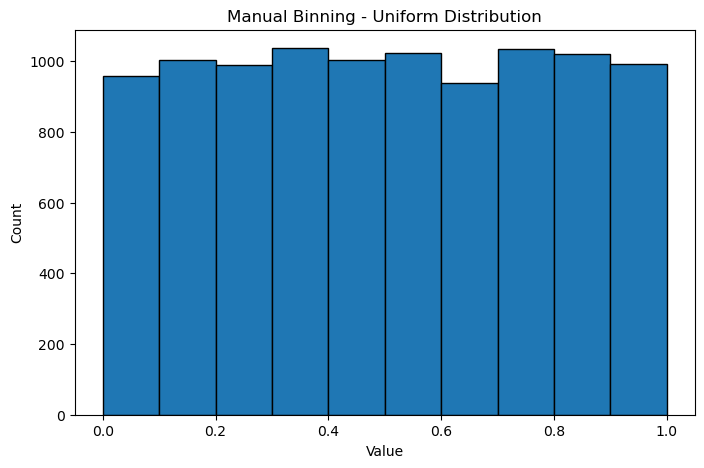

In [91]:
# Uniform plot
uniform_centers = (uniform_bins[:-1] + uniform_bins[1:]) / 2
uniform_widths = np.diff(uniform_bins)

plt.figure(figsize=(8, 5))
plt.bar(uniform_centers, uniform_counts, width=uniform_widths, edgecolor="black")
plt.xlabel("Value")
plt.ylabel("Count")
plt.title("Manual Binning - Uniform Distribution")
plt.show()

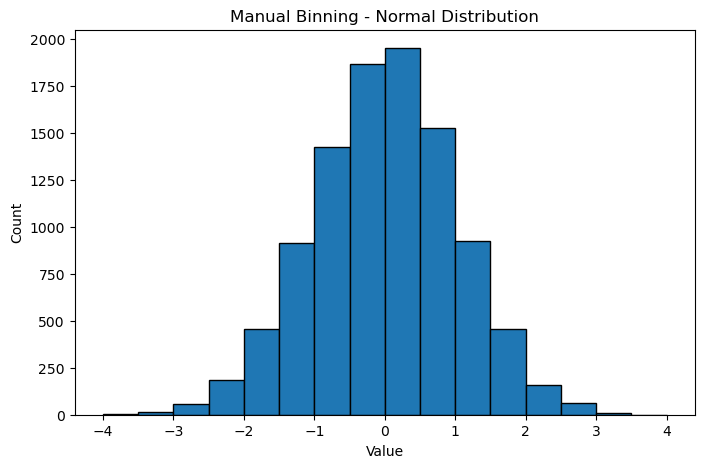

In [92]:
# Normal plot
normal_centers = (normal_bins[:-1] + normal_bins[1:]) / 2
normal_widths = np.diff(normal_bins)

plt.figure(figsize=(8, 5))
plt.bar(normal_centers, normal_counts, width=normal_widths, edgecolor="black")
plt.xlabel("Value")
plt.ylabel("Count")
plt.title("Manual Binning - Normal Distribution")
plt.show()

In [93]:
# Compare different bin numbers for uniform distribution
uniform_bins_5 = np.linspace(0, 1, 6)       # 5 bins
uniform_bins_20 = np.linspace(0, 1, 21)     # 20 bins

uniform_counts_5 = manual_bin_counts(uniform_data, uniform_bins_5)
uniform_counts_20 = manual_bin_counts(uniform_data, uniform_bins_20)

uniform_comparison = pd.DataFrame({
    "number_of_bins": [5, 20],
    "average_count_per_bin": [uniform_counts_5.mean(), uniform_counts_20.mean()],
    "minimum_count": [uniform_counts_5.min(), uniform_counts_20.min()],
    "maximum_count": [uniform_counts_5.max(), uniform_counts_20.max()]
})

display(uniform_comparison)

,number_of_bins,average_count_per_bin,minimum_count,maximum_count
0,5,2000.0,1961,2027
1,20,500.0,462,559


In [94]:
# Compare different bin numbers for normal distribution
normal_bins_8 = np.linspace(-4, 4, 9)        # 8 bins
normal_bins_32 = np.linspace(-4, 4, 33)      # 32 bins

normal_counts_8 = manual_bin_counts(normal_data, normal_bins_8)
normal_counts_32 = manual_bin_counts(normal_data, normal_bins_32)

normal_comparison = pd.DataFrame({
    "number_of_bins": [8, 32],
    "average_count_per_bin": [normal_counts_8.mean(), normal_counts_32.mean()],
    "minimum_count": [normal_counts_8.min(), normal_counts_32.min()],
    "maximum_count": [normal_counts_8.max(), normal_counts_32.max()]
})

display(normal_comparison)

,number_of_bins,average_count_per_bin,minimum_count,maximum_count
0,8,1250.0,11,3479
1,32,312.5,0,983


In [95]:
# Optional check only
uniform_check, _ = np.histogram(uniform_data, bins=uniform_bins)
normal_check, _ = np.histogram(normal_data, bins=normal_bins)

print("Uniform manual result matches np.histogram:", np.array_equal(uniform_counts, uniform_check))
print("Normal manual result matches np.histogram:", np.array_equal(normal_counts, normal_check))

Uniform manual result matches np.histogram: True
Normal manual result matches np.histogram: True


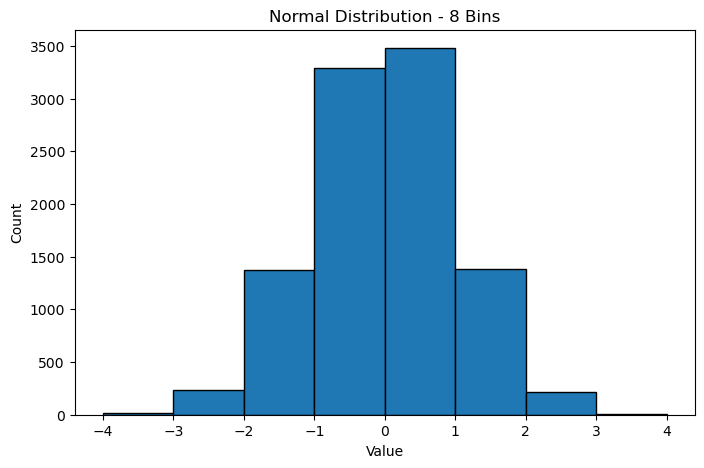

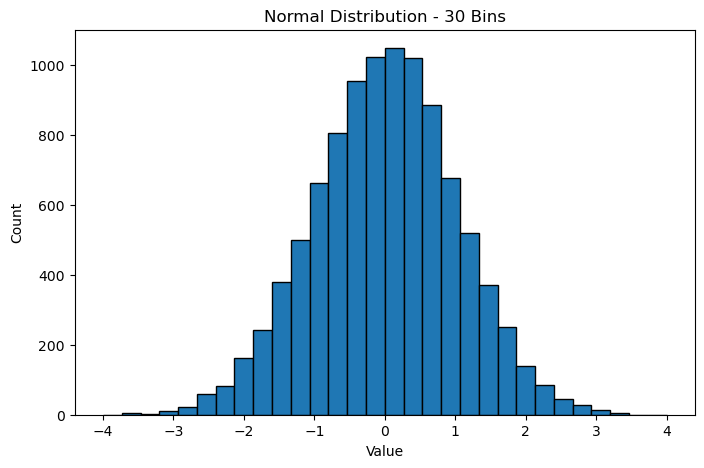

In [96]:
normal_bins_8 = np.linspace(-4, 4, 9)
normal_bins_30 = np.linspace(-4, 4, 31)

normal_counts_8 = manual_bin_counts(normal_data, normal_bins_8)
normal_counts_30 = manual_bin_counts(normal_data, normal_bins_30)

# Plot for 8 bins
centers_8 = (normal_bins_8[:-1] + normal_bins_8[1:]) / 2
plt.figure(figsize=(8,5))
plt.bar(centers_8, normal_counts_8, width=np.diff(normal_bins_8), align='center', edgecolor='black')
plt.xlabel("Value")
plt.ylabel("Count")
plt.title("Normal Distribution - 8 Bins")
plt.show()

# Plot for 30 bins
centers_30 = (normal_bins_30[:-1] + normal_bins_30[1:]) / 2
plt.figure(figsize=(8,5))
plt.bar(centers_30, normal_counts_30, width=np.diff(normal_bins_30), align='center', edgecolor='black')
plt.xlabel("Value")
plt.ylabel("Count")
plt.title("Normal Distribution - 30 Bins")
plt.show()

<h1 style="color:crimson;">Homework 1 - Item 3</h1>
<h2 style="color:navy;">Write your own RMSE function</h2>


In [111]:
import numpy as np
import pandas as pd

In [112]:
def rmse(y_hat, y):
    y_hat = np.array(y_hat)
    y = np.array(y)

    if y_hat.shape != y.shape:
        raise ValueError("y_hat and y must have the same shape.")

    return np.sqrt(np.mean((y_hat - y) ** 2))

In [113]:
# Test 1: identical arrays -> RMSE should be 0
y = np.array([1, 2, 3, 4])
y_hat = np.array([1, 2, 3, 4])

print("Test 1 RMSE =", rmse(y_hat, y))

Test 1 RMSE = 0.0


y_hat=mean value
y=random numbers

In [114]:
# Test 2: constant offset of 3 -> RMSE should be 3
y = np.array([1, 2, 3, 4])
y_hat = y + 3

print("Test 2 RMSE =", rmse(y_hat, y))

Test 2 RMSE = 3.0


In [117]:
# Test 3: shape mismatch should raise an error
try:
    y = np.array([1, 2, 3])
    y_hat = np.array([1, 2])
    print(rmse(y_hat, y))
except ValueError as e:
    print("Shape error test:", e)

Shape error test: y_hat and y must have the same shape.


In [118]:
rng = np.random.default_rng(1)

# Generate 10,000 numbers with mean 50 and standard deviation 10
data = rng.normal(50, 10, 10_000)

# Shuffle the data
rng.shuffle(data)

# Split into 5 pieces
splits = np.array_split(data, 5)

In [119]:
results = []

for i, part in enumerate(splits):
    y_hat = np.full(part.shape, part.mean())   # prediction = mean of that split

    rmse_custom = rmse(y_hat, part)
    rmse_numpy = np.sqrt(np.mean((y_hat - part) ** 2))
    std_part = np.std(part)

    results.append({
        "split": i + 1,
        "n_values": len(part),
        "mean_of_split": part.mean(),
        "RMSE_custom": rmse_custom,
        "RMSE_numpy_one_liner": rmse_numpy,
        "np.std(part)": std_part
    })

results_table = pd.DataFrame(results)
display(results_table)

,split,n_values,mean_of_split,RMSE_custom,RMSE_numpy_one_liner,np.std(part)
0,1,2000,49.649803,9.732144,9.732144,9.732144
1,2,2000,49.996640,10.038414,10.038414,10.038414
2,3,2000,49.849841,10.096837,10.096837,10.096837
3,4,2000,49.920673,9.992397,9.992397,9.992397
4,5,2000,50.037398,10.056109,10.056109,10.056109


In [120]:
results_table["custom_minus_numpy"] = results_table["RMSE_custom"] - results_table["RMSE_numpy_one_liner"]
results_table["custom_minus_std"] = results_table["RMSE_custom"] - results_table["np.std(part)"]

display(results_table)

,split,n_values,mean_of_split,RMSE_custom,RMSE_numpy_one_liner,np.std(part),custom_minus_numpy,custom_minus_std
0,1,2000,49.649803,9.732144,9.732144,9.732144,0.0,0.0
1,2,2000,49.996640,10.038414,10.038414,10.038414,0.0,0.0
2,3,2000,49.849841,10.096837,10.096837,10.096837,0.0,0.0
3,4,2000,49.920673,9.992397,9.992397,9.992397,0.0,0.0
4,5,2000,50.037398,10.056109,10.056109,10.056109,0.0,0.0


In [1]:
%pip install ase

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\İpek\Desktop\ML Homeworks
['.ipynb_checkpoints', 'archive', 'archive.zip', 'Fatigue_data.csv', 'Lecture07.ipynb', 'Lecture_5_2026F_upload.pdf', 'Lecture_6_2026F.pdf', 'TiAlV_Atomic_Data_HW1', 'Untitled.ipynb', 'view.htm']


In [3]:
from ase.io import read

atoms = read(
    "ti64_combined_data_Apr08.extxyz",
    index=0
)

print(atoms)

FileNotFoundError: [Errno 2] No such file or directory: 'ti64_combined_data_Apr08.extxyz'

In [4]:
import os

print(os.getcwd())

C:\Users\İpek\Desktop\ML Homeworks


In [5]:
read("ti64_combined_data_Apr08.extxyz")

FileNotFoundError: [Errno 2] No such file or directory: 'ti64_combined_data_Apr08.extxyz'

In [6]:
from pathlib import Path

print("EXTXYZ files:")

for file in Path.cwd().rglob("*.extxyz"):
    print(file)

EXTXYZ files:


In [8]:
from ase.io import read

file_path = r"C:\Users\İpek\Downloads\ti64_combined_data_Apr08.extxyz"

atoms = read(file_path, index=0)

print(atoms)

Atoms(symbols='AlTi3', pbc=True, cell=[[8.743489, 0.0, 0.0], [-7e-06, 2.677143, 0.0], [-7e-06, -0.892385, 2.524033]], QM_forces=...)


In [9]:
print("Formula:", atoms.get_chemical_formula())
print("Number of atoms:", len(atoms))
print("DFT Energy:", atoms.info.get("QM_energy"))
print("Configuration type:", atoms.info.get("config_type"))

Formula: AlTi3
Number of atoms: 4
DFT Energy: -4892.174068022
Configuration type: bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_rattle_0.10


In [10]:
total_energy = atoms.info["QM_energy"]

n_atoms = len(atoms)

energy_per_atom = total_energy / n_atoms

print("Total energy:", total_energy, "eV")
print("Energy per atom:", energy_per_atom, "eV/atom")

Total energy: -4892.174068022 eV
Energy per atom: -1223.0435170055 eV/atom


In [11]:
from ase.io import iread

for i, atoms in enumerate(iread(file_path, index=":")):

    print(
        i,
        atoms.get_chemical_formula(),
        len(atoms),
        atoms.info.get("config_type")
    )

    if i == 9:
        break

0 AlTi3 4 bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_rattle_0.10
1 AlTi3 4 bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_rattle_0.10
2 AlTi3 4 bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_rattle_0.10
3 Ti3V 4 bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_rattle_0.10
4 AlTi3 4 bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_rattle_0.10
5 Ti3V 4 bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_rattle_0.10
6 Ti3V 4 bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_rattle_0.10
7 AlTi3 4 bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_rattle_0.10
8 AlTi3 4 bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_rattle_0.10
9 AlTi3 4 bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_rattle_0.10


In [12]:
from collections import Counter
from ase.io import iread

import pandas as pd
import numpy as np

rows = []

for i, structure in enumerate(iread(file_path, index=":")):

    counts = Counter(structure.get_chemical_symbols())

    n_atoms = len(structure)

    energy = structure.info.get("QM_energy", np.nan)

    config_type = structure.info.get("config_type", "unknown")

    rows.append({
        "frame_id": i,
        "n_atoms": n_atoms,
        "n_Ti": counts.get("Ti", 0),
        "n_Al": counts.get("Al", 0),
        "n_V": counts.get("V", 0),
        "config_type": config_type,
        "structure_family": config_type.split("_")[0],
        "volume_per_atom_A3": structure.get_volume() / n_atoms,
        "QM_energy": energy,
        "QM_energy_per_atom_eV": energy / n_atoms
    })

df_all = pd.DataFrame(rows)

print("Dataset shape:", df_all.shape)

display(df_all.head(10))

Dataset shape: (8507, 10)


,frame_id,n_atoms,n_Ti,n_Al,n_V,config_type,structure_family,volume_per_atom_A3,QM_energy,QM_energy_per_atom_eV
0,0,4,3,1,0,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,bcc,14.770370,-4892.174068,-1223.043517
1,1,4,3,1,0,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,bcc,14.770370,-4892.079715,-1223.019929
2,2,4,3,1,0,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,bcc,14.770370,-4892.290688,-1223.072672
3,3,4,3,0,1,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,bcc,14.770370,-6854.765419,-1713.691355
4,4,4,3,1,0,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,bcc,14.770370,-4892.089692,-1223.022423
5,5,4,3,0,1,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,bcc,14.770370,-6855.065613,-1713.766403
6,6,4,3,0,1,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,bcc,15.241729,-6855.216405,-1713.804101
7,7,4,3,1,0,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,bcc,15.241729,-4891.851550,-1222.962888
8,8,4,3,1,0,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,bcc,15.241729,-4892.423604,-1223.105901
9,9,4,3,1,0,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,bcc,15.241729,-4892.304301,-1223.076075


In [13]:
print(df_all["structure_family"].value_counts())

structure_family
bcc       3107
hcp       2633
hex       2441
liquid     304
ACE         22
Name: count, dtype: int64


In [14]:
df_selected = df_all[
    (df_all["n_Ti"] == 10) &
    (df_all["n_Al"] == 1) &
    (df_all["n_V"] == 1) &
    (df_all["structure_family"].isin(["bcc", "hcp", "hex"]))
].copy()

print("Selected configurations:", len(df_selected))

print(df_selected["structure_family"].value_counts())

display(df_selected.head())

Selected configurations: 454
structure_family
hex    231
hcp    118
bcc    105
Name: count, dtype: int64


,frame_id,n_atoms,n_Ti,n_Al,n_V,config_type,structure_family,volume_per_atom_A3,QM_energy,QM_energy_per_atom_eV
2496,2496,12,10,1,1,bcc_shearchem_phgr_12x12x12_rattle_0.05_symshe...,bcc,17.094105,-18123.022272,-1510.251856
2498,2498,12,10,1,1,bcc_shearchem_phgr_12x12x12_rattle_0.05_symshe...,bcc,17.544903,-18122.898997,-1510.241583
2503,2503,12,10,1,1,bcc_shearchem_phgr_12x12x12_rattle_0.05_symshe...,bcc,17.161764,-18122.949412,-1510.245784
2511,2511,12,10,1,1,bcc_shearchem_phgr_12x12x12_rattle_0.05_symshe...,bcc,16.890066,-18123.019074,-1510.251590
2512,2512,12,10,1,1,bcc_shearchem_phgr_12x12x12_rattle_0.05_symshe...,bcc,16.922399,-18122.963473,-1510.246956


In [15]:
print("Missing values:")

print(df_selected.isnull().sum())

Missing values:
frame_id                 0
n_atoms                  0
n_Ti                     0
n_Al                     0
n_V                      0
config_type              0
structure_family         0
volume_per_atom_A3       0
QM_energy                0
QM_energy_per_atom_eV    0
dtype: int64


In [16]:
print(df_selected.dtypes)

frame_id                   int64
n_atoms                    int64
n_Ti                       int64
n_Al                       int64
n_V                        int64
config_type               object
structure_family          object
volume_per_atom_A3       float64
QM_energy                float64
QM_energy_per_atom_eV    float64
dtype: object


In [17]:
print("Invalid volumes:")

print((df_selected["volume_per_atom_A3"] <= 0).sum())

print("Non-finite energies:")

print(
    (~np.isfinite(df_selected["QM_energy_per_atom_eV"])).sum()
)

Invalid volumes:
0
Non-finite energies:
0


# HW1-4: Data Collection and Preparation

## Predicting DFT Configurational Energies in Ti-Al-V Alloys

In [2]:
from pathlib import Path
from ase.io import read
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Paste the full path of the downloaded dataset
file_path = input("Enter the full path of your EXTXYZ file: ")

DATA_PATH = Path(file_path.strip().strip('"'))

print("File exists:", DATA_PATH.is_file())

# Read only the first atomic configuration
atoms = read(DATA_PATH, index=0)

print("Number of atoms:", len(atoms))
print("Chemical formula:", atoms.get_chemical_formula())
print("Cell volume:", atoms.get_volume())

print("\nAvailable metadata:")
print(atoms.info)

print("\nAvailable atomic arrays:")
print(list(atoms.arrays.keys()))

print("\nAvailable calculator results:")
print(list(atoms.calc.results.keys()) if atoms.calc else "None")

Enter the full path of your EXTXYZ file:  "C:\Users\İpek\Downloads\ti64_combined_data_Apr08.extxyz"


File exists: True
Number of atoms: 4
Chemical formula: AlTi3
Cell volume: 59.08148006856604

Available metadata:
{'QM_energy': np.float64(-4892.174068022), 'QM_virial': array([6.41915893, 0.12947448, 0.32199176, 0.12947448, 6.57998555,
       0.97254432, 0.32199176, 0.97254432, 7.26669886]), 'config_type': 'bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_rattle_0.10'}

Available atomic arrays:
['numbers', 'positions', 'QM_forces']

Available calculator results:
None


In [3]:
energy = atoms.info["QM_energy"]

print("DFT total energy:", energy, "eV")
print("DFT energy per atom:", energy / len(atoms), "eV/atom")

DFT total energy: -4892.174068022 eV
DFT energy per atom: -1223.0435170055 eV/atom


In [4]:
from ase.io import iread
from collections import Counter
import pandas as pd

data = []

# Read the first 50 atomic configurations
for i, atoms in enumerate(iread(DATA_PATH, index=":")):

    if i >= 50:
        break

    counts = Counter(atoms.get_chemical_symbols())

    energy = atoms.info.get("QM_energy")

    data.append({
        "structure_id": i,
        "n_atoms": len(atoms),

        "n_Ti": counts.get("Ti", 0),
        "n_Al": counts.get("Al", 0),
        "n_V": counts.get("V", 0),

        "config_type": atoms.info.get("config_type"),

        "volume_A3": atoms.get_volume(),

        "DFT_energy_eV": energy,

        "DFT_energy_per_atom_eV":
            energy / len(atoms) if energy is not None else None
    })

df = pd.DataFrame(data)

print("Dataset shape:", df.shape)

display(df.head(10))

Dataset shape: (50, 9)


,structure_id,n_atoms,n_Ti,n_Al,n_V,config_type,volume_A3,DFT_energy_eV,DFT_energy_per_atom_eV
0,0,4,3,1,0,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,59.081480,-4892.174068,-1223.043517
1,1,4,3,1,0,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,59.081480,-4892.079715,-1223.019929
2,2,4,3,1,0,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,59.081480,-4892.290688,-1223.072672
3,3,4,3,0,1,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,59.081480,-6854.765419,-1713.691355
4,4,4,3,1,0,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,59.081480,-4892.089692,-1223.022423
5,5,4,3,0,1,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,59.081480,-6855.065613,-1713.766403
6,6,4,3,0,1,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,60.966916,-6855.216405,-1713.804101
7,7,4,3,1,0,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,60.966916,-4891.851550,-1222.962888
8,8,4,3,1,0,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,60.966916,-4892.423604,-1223.105901
9,9,4,3,1,0,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,60.966916,-4892.304301,-1223.076075


In [5]:
print("Configuration types:")
print(df["config_type"].value_counts())

print("\nChemical composition:")
display(df[["n_Ti", "n_Al", "n_V"]].drop_duplicates())

print("\nMissing values:")
print(df.isnull().sum())

Configuration types:
config_type
bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_rattle_0.10    50
Name: count, dtype: int64

Chemical composition:


,n_Ti,n_Al,n_V
0,3,1,0
3,3,0,1



Missing values:
structure_id              0
n_atoms                   0
n_Ti                      0
n_Al                      0
n_V                       0
config_type               0
volume_A3                 0
DFT_energy_eV             0
DFT_energy_per_atom_eV    0
dtype: int64


## HW1-4 — Full Dataset Inventory

The first 50 configurations belong to the BCC family.
The full dataset is examined to identify suitable HCP
Ti-Al-V configurations and chemical composition groups.

In [6]:
from ase.io import iread
from collections import Counter
import pandas as pd
import numpy as np

inventory = []

for i, atoms in enumerate(iread(DATA_PATH, index=":")):

    counts = Counter(atoms.get_chemical_symbols())

    energy = atoms.info.get("QM_energy", np.nan)

    inventory.append({
        "structure_id": i,
        "config_type": atoms.info.get("config_type", "unknown"),
        "n_atoms": len(atoms),
        "n_Ti": counts.get("Ti", 0),
        "n_Al": counts.get("Al", 0),
        "n_V": counts.get("V", 0),
        "volume_per_atom": atoms.get_volume() / len(atoms),
        "DFT_energy_per_atom": energy / len(atoms)
    })

    if (i + 1) % 2000 == 0:
        print(f"Read {i + 1} configurations")

df_all = pd.DataFrame(inventory)

print("Total configurations:", len(df_all))
print("Total columns:", df_all.shape[1])

Read 2000 configurations
Read 4000 configurations
Read 6000 configurations
Read 8000 configurations
Total configurations: 8507
Total columns: 8


In [7]:
print("Configuration types:")

display(
    df_all["config_type"]
    .value_counts()
    .reset_index(name="count")
)

Configuration types:


,config_type,count
0,bcc_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,2495
1,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,2031
2,hex_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,1965
3,hcp_shearchem_phgr_6x6x6_rattle_0.05_symshear_...,304
4,hex_shearchem_phgr_4x4x4_rattle_0.05_symshear_...,304
5,liquid,304
6,bcc_shearchem_phgr_12x12x12_rattle_0.05_symshe...,288
7,bcc_shearchem_phgr_12x12x12_rattle_0.05_symshe...,288
8,hcp_shearchem_phgr_6x6x6_rattle_0.05_symshear_...,285
9,hex_shearchem_phgr_4x4x4_rattle_0.05_symshear_...,160


In [8]:
ternary = df_all[
    (df_all["n_Ti"] > 0) &
    (df_all["n_Al"] > 0) &
    (df_all["n_V"] > 0)
]

print("Ti-Al-V ternary configurations:", len(ternary))

print("\nMost common compositions:")

composition_counts = (
    df_all
    .groupby(["n_atoms", "n_Ti", "n_Al", "n_V"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(composition_counts.head(20))

Ti-Al-V ternary configurations: 3538

Most common compositions:


,n_atoms,n_Ti,n_Al,n_V,count
6,8,6,2,0,1380
5,8,6,1,1,910
9,12,10,2,0,691
14,16,13,2,1,646
15,16,13,3,0,634
20,24,20,3,1,614
11,12,11,1,0,612
21,24,20,4,0,473
8,12,10,1,1,454
1,4,3,1,0,421


## HW1-4 — Selection of HCP Ti-Al-V Configurations

The dataset contains several crystal structure families.
Only configurations with HCP-related labels and all three
elements (Ti, Al, V) are selected for further analysis.

In [10]:
# Select HCP-related configurations
hcp = df_all[
    df_all["config_type"].str.startswith("hcp_", na=False)
].copy()

# Select structures containing Ti, Al and V
hcp_ternary = hcp[
    (hcp["n_Ti"] > 0) &
    (hcp["n_Al"] > 0) &
    (hcp["n_V"] > 0)
].copy()

print("All HCP-labeled configurations:", len(hcp))
print("HCP-labeled Ti-Al-V configurations:", len(hcp_ternary))

print("\nConfiguration families:")
print(hcp_ternary["config_type"].value_counts())

All HCP-labeled configurations: 2633
HCP-labeled Ti-Al-V configurations: 1125

Configuration families:
config_type
hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_rattle_0.10                        994
hcp_shearchem_phgr_6x6x6_rattle_0.05_symshear_0.01                              71
hcp_shearchem_phgr_6x6x6_rattle_0.05_symshear_0.01_cparam_rand_0.90_to_1.02     47
hcp_Ti80V10Al10_VV_geomoptiace                                                  13
Name: count, dtype: int64


In [11]:
hcp_groups = (
    hcp_ternary
    .groupby(["n_atoms", "n_Ti", "n_Al", "n_V"])
    .agg(
        n_configurations=("structure_id", "count"),
        min_volume=("volume_per_atom", "min"),
        max_volume=("volume_per_atom", "max"),
        min_energy=("DFT_energy_per_atom", "min"),
        max_energy=("DFT_energy_per_atom", "max")
    )
    .reset_index()
    .sort_values("n_configurations", ascending=False)
)

display(hcp_groups)

,n_atoms,n_Ti,n_Al,n_V,n_configurations,min_volume,max_volume,min_energy,max_energy
3,16,13,2,1,646,14.905198,18.448778,-1438.540001,-1438.215383
2,16,13,1,2,202,14.905198,18.448778,-1561.166153,-1560.917688
0,8,6,1,1,146,14.905199,18.448775,-1468.548072,-1468.277525
1,12,10,1,1,118,12.905873,18.351411,-1510.323111,-1509.769784
4,54,42,5,7,13,16.656805,16.656805,-1518.836242,-1518.790288


## HW1-4 — Selection of Comparable Atomic Configurations

To investigate the influence of local chemical arrangements
on DFT energy, HCP-labeled structures with identical
stoichiometry are selected.

Cell volume and configuration type are also examined
to reduce the influence of unrelated structural differences.

In [12]:
# Select structures with composition Ti13Al2V

selected = hcp_ternary[
    (hcp_ternary["n_atoms"] == 16) &
    (hcp_ternary["n_Ti"] == 13) &
    (hcp_ternary["n_Al"] == 2) &
    (hcp_ternary["n_V"] == 1)
].copy()

print("Selected configurations:", len(selected))

# Group structures with approximately equal volumes
selected["volume_group"] = selected["volume_per_atom"].round(3)

# Compare the volume groups
volume_summary = (
    selected
    .groupby(["config_type", "volume_group"])
    .agg(
        n_configurations=("structure_id", "count"),
        min_energy=("DFT_energy_per_atom", "min"),
        max_energy=("DFT_energy_per_atom", "max")
    )
    .reset_index()
    .sort_values("n_configurations", ascending=False)
)

display(volume_summary.head(15))

Selected configurations: 646


,config_type,volume_group,n_configurations,min_energy,max_energy
4,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16.868,88,-1438.518119,-1438.413490
0,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,14.905,86,-1438.421519,-1438.215383
5,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,17.385,84,-1438.540001,-1438.422550
7,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,18.449,81,-1438.499717,-1438.417230
6,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,17.911,80,-1438.506747,-1438.416608
1,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,15.381,78,-1438.449536,-1438.317405
2,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,15.867,75,-1438.490452,-1438.343305
3,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16.362,74,-1438.522708,-1438.394980


## HW1-4 — Preparation of the Initial Dataset

A subset of 50 HCP-labeled Ti13Al2V configurations
was selected from the largest volume group.

All selected configurations have the same composition
and approximately equal volume per atom.

In [13]:
# Select the largest volume group
best_group = volume_summary.iloc[0]

df_group = selected[
    (selected["config_type"] == best_group["config_type"]) &
    (selected["volume_group"] == best_group["volume_group"])
].copy()

print("Available configurations:", len(df_group))

# Randomly select 50 reproducible configurations
df_hw4 = df_group.sample(
    n=50,
    random_state=42
).copy()

# Sort by structure ID and reset the index
df_hw4 = df_hw4.sort_values("structure_id").reset_index(drop=True)

print("Selected dataset shape:", df_hw4.shape)

display(df_hw4.head(10))

Available configurations: 88
Selected dataset shape: (50, 9)


,structure_id,config_type,n_atoms,n_Ti,n_Al,n_V,volume_per_atom,DFT_energy_per_atom,volume_group
0,3623,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868347,-1438.465745,16.868
1,3672,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868347,-1438.476792,16.868
2,3673,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868347,-1438.444597,16.868
3,3675,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868347,-1438.477459,16.868
4,3719,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868349,-1438.515500,16.868
5,3720,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868349,-1438.483628,16.868
6,3721,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868349,-1438.443141,16.868
7,3723,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868349,-1438.461830,16.868
8,3767,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868347,-1438.464499,16.868
9,3768,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868347,-1438.425489,16.868


In [14]:
print("Missing values:")
print(df_hw4.isnull().sum())

print("\nDuplicate structure IDs:")
print(df_hw4["structure_id"].duplicated().sum())

print("\nVolume statistics:")
print(df_hw4["volume_per_atom"].describe())

print("\nDFT energy statistics:")
print(df_hw4["DFT_energy_per_atom"].describe())

print("\nNumber of unique compositions:")
print(
    df_hw4[["n_Ti", "n_Al", "n_V"]]
    .drop_duplicates()
    .shape[0]
)

Missing values:
structure_id           0
config_type            0
n_atoms                0
n_Ti                   0
n_Al                   0
n_V                    0
volume_per_atom        0
DFT_energy_per_atom    0
volume_group           0
dtype: int64

Duplicate structure IDs:
0

Volume statistics:
count    50.000000
mean     16.868349
std       0.000001
min      16.868346
25%      16.868347
50%      16.868348
75%      16.868349
max      16.868353
Name: volume_per_atom, dtype: float64

DFT energy statistics:
count      50.000000
mean    -1438.477401
std         0.023523
min     -1438.516285
25%     -1438.492017
50%     -1438.478498
75%     -1438.464301
max     -1438.416974
Name: DFT_energy_per_atom, dtype: float64

Number of unique compositions:
1


In [15]:
from ase.io import iread
from ase.neighborlist import neighbor_list
import numpy as np

# Get the original ID of our first selected structure
chosen_id = int(df_hw4.loc[0, "structure_id"])

# Find this configuration in the original EXTXYZ file
for i, a in enumerate(iread(DATA_PATH, index=":")):
    if i == chosen_id:
        atoms_test = a
        break

print("Structure ID:", chosen_id)
print("Chemical formula:", atoms_test.get_chemical_formula())
print("Periodic boundaries:", atoms_test.pbc)

Structure ID: 3623
Chemical formula: Al2Ti13V
Periodic boundaries: [ True  True  True]


In [16]:
# Find neighboring atoms within 5 Angstroms
i_atoms, j_atoms, distances = neighbor_list(
    "ijd",
    atoms_test,
    cutoff=5.0
)

# Examine the neighbors of atom 0
nearest_distances = np.sort(distances[i_atoms == 0])

print("Number of neighbors within 5 Å:", len(nearest_distances))

print("\nNeighbor distances (Å):")
print(np.round(nearest_distances[:20], 3))

if len(nearest_distances) >= 13:
    print("\n12th neighbor:", round(nearest_distances[11], 3), "Å")
    print("13th neighbor:", round(nearest_distances[12], 3), "Å")

Number of neighbors within 5 Å: 28

Neighbor distances (Å):
[2.627 2.665 2.703 2.81  2.875 2.88  2.909 2.909 3.041 3.046 3.13  3.164
 3.904 3.979 4.036 4.072 4.109 4.304 4.605 4.605]

12th neighbor: 3.164 Å
13th neighbor: 3.904 Å


In [26]:
import numpy as np
from ase.neighborlist import neighbor_list

def calculate_descriptors(atoms):

    # Get the chemical symbols of all atoms
    symbols = np.array(atoms.get_chemical_symbols())

    # Find neighboring atoms within 5 Angstroms
    i_atoms, j_atoms, distances = neighbor_list(
        "ijd", atoms, cutoff=5.0
    )

    pair_list = []
    first_shell_distances = []
    shell_gaps = []

    # Examine each atom separately
    for i in range(len(atoms)):

        mask = (i_atoms == i)

        neighbor_ids = j_atoms[mask]
        neighbor_distances = distances[mask]

        # Sort neighbors by distance
        order = np.argsort(neighbor_distances)

        neighbor_ids = neighbor_ids[order]
        neighbor_distances = neighbor_distances[order]

        # Check if enough neighbors exist
        if len(neighbor_ids) < 13:
            raise ValueError("Not enough neighbors within 5 Å")

        # Select the first 12 nearest neighbors
        first12 = neighbor_ids[:12]

        # Store nearest-neighbor distances
        first_shell_distances.extend(neighbor_distances[:12])

        # Calculate the gap between 12th and 13th neighbors
        shell_gaps.append(
            neighbor_distances[12] - neighbor_distances[11]
        )

        # Store chemical element pairs
        for j in first12:
            pair_list.append((symbols[i], symbols[j]))

    # Calculate atomic concentrations
    c_Al = np.mean(symbols == "Al")
    c_V = np.mean(symbols == "V")

    # Calculate conditional neighbor probabilities
    def probability(center, neighbor):

        pairs = [p for p in pair_list if p[0] == center]

        if len(pairs) == 0:
            return np.nan

        return sum(p[1] == neighbor for p in pairs) / len(pairs)

    # Calculate Warren-Cowley SRO parameters
    sro_Ti_Al = 1 - probability("Ti", "Al") / c_Al
    sro_Ti_V = 1 - probability("Ti", "V") / c_V
    sro_Al_V = 1 - probability("Al", "V") / c_V

    # Return all calculated descriptors
    return {
        "SRO_Ti_Al": sro_Ti_Al,
        "SRO_Ti_V": sro_Ti_V,
        "SRO_Al_V": sro_Al_V,
        "mean_neighbor_distance": np.mean(first_shell_distances),
        "std_neighbor_distance": np.std(first_shell_distances),
        "min_shell_gap": np.min(shell_gaps)
    }

In [27]:
test_descriptors = calculate_descriptors(atoms_test)

print("Returned type:", type(test_descriptors))

print("\nCalculated descriptors:")

for key, value in test_descriptors.items():
    print(key, ":", round(value, 4))

Returned type: <class 'dict'>

Calculated descriptors:
SRO_Ti_Al : -0.0256
SRO_Ti_V : -0.0256
SRO_Al_V : 1.0
mean_neighbor_distance : 2.8839
std_neighbor_distance : 0.145
min_shell_gap : 0.5201


## HW1-4 — Extraction of Atomic Descriptors

First-neighbor chemical ordering and geometric descriptors
were calculated for the 50 selected Ti13Al2V configurations.

These descriptors will be used to investigate variations
in DFT energy per atom.

In [28]:
from ase.io import iread
import pandas as pd

# IDs of our 50 selected configurations
selected_ids = set(df_hw4["structure_id"])

results = []

# Read the original atomic structures
for i, atoms in enumerate(iread(DATA_PATH, index=":")):

    if i in selected_ids:

        # Calculate SRO and geometric descriptors
        descriptors = calculate_descriptors(atoms)

        # Store the original structure ID
        descriptors["structure_id"] = i

        results.append(descriptors)

    # Stop after finding all selected configurations
    if len(results) == len(selected_ids):
        break

# Convert results into a DataFrame
features = pd.DataFrame(results)

# Check that all 50 structures were found
assert len(features) == 50, "Some structures were not found!"

# Prevent duplicate columns if this cell is run again
old_columns = [
    col for col in features.columns
    if col != "structure_id" and col in df_hw4.columns
]

df_hw4 = df_hw4.drop(columns=old_columns)

# Combine the original data and new descriptors
df_hw4 = df_hw4.merge(
    features,
    on="structure_id",
    how="left",
    validate="one_to_one"
)

print("Final dataset shape:", df_hw4.shape)

display(df_hw4.head(10))

Final dataset shape: (50, 15)


,structure_id,config_type,n_atoms,n_Ti,n_Al,n_V,volume_per_atom,DFT_energy_per_atom,volume_group,SRO_Ti_Al,SRO_Ti_V,SRO_Al_V,mean_neighbor_distance,std_neighbor_distance,min_shell_gap
0,3623,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868347,-1438.465745,16.868,-0.025641,-0.025641,1.000000,2.883898,0.144956,0.520099
1,3672,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868347,-1438.476792,16.868,-0.025641,-0.230769,1.000000,2.884957,0.127658,0.484013
2,3673,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868347,-1438.444597,16.868,-0.025641,-0.230769,1.000000,2.886435,0.145872,0.615052
3,3675,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868347,-1438.477459,16.868,-0.076923,0.076923,-1.000000,2.885910,0.146913,0.434846
4,3719,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868349,-1438.515500,16.868,-0.179487,-0.128205,0.333333,2.883833,0.127323,0.638492
5,3720,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868349,-1438.483628,16.868,-0.025641,-0.025641,-0.333333,2.886110,0.143979,0.607962
6,3721,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868349,-1438.443141,16.868,-0.179487,-0.128205,0.333333,2.888200,0.176334,0.273222
7,3723,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868349,-1438.461830,16.868,0.128205,0.076923,-1.000000,2.886555,0.149290,0.423460
8,3767,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868347,-1438.464499,16.868,-0.128205,-0.025641,-0.333333,2.887433,0.162481,0.503008
9,3768,hcp_chempeturb_phgr8x8x8_cpara_0.95_to_1.02_ra...,16,13,2,1,16.868347,-1438.425489,16.868,0.128205,0.076923,-1.000000,2.886365,0.169313,0.444704


In [29]:
sro_columns = [
    "SRO_Ti_Al",
    "SRO_Ti_V",
    "SRO_Al_V"
]

geometry_columns = [
    "mean_neighbor_distance",
    "std_neighbor_distance",
    "min_shell_gap"
]

# Statistical summary
display(
    df_hw4[sro_columns + geometry_columns]
    .describe()
    .T
)

# Number of distinct SRO values
print("Number of unique SRO values:")

print(
    df_hw4[sro_columns]
    .round(6)
    .nunique()
)

# Missing values
print("\nMissing descriptor values:")

print(
    df_hw4[sro_columns + geometry_columns]
    .isnull()
    .sum()
)

,count,mean,std,min,25%,50%,75%,max
SRO_Ti_Al,50.0,-0.013333,0.149981,-0.179487,-0.076923,-0.025641,0.025641,0.692308
SRO_Ti_V,50.0,-0.021538,0.132615,-0.230769,-0.128205,-0.025641,0.076923,0.384615
SRO_Al_V,50.0,0.093333,0.696737,-1.000000,-0.333333,0.333333,0.833333,1.000000
mean_neighbor_distance,50.0,2.885583,0.001663,2.881161,2.884689,2.885733,2.886396,2.888926
std_neighbor_distance,50.0,0.139082,0.016564,0.092479,0.129555,0.141918,0.149695,0.176334
min_shell_gap,50.0,0.557353,0.111587,0.245244,0.504948,0.556095,0.615142,0.825170


Number of unique SRO values:
SRO_Ti_Al    10
SRO_Ti_V      6
SRO_Al_V      4
dtype: int64

Missing descriptor values:
SRO_Ti_Al                 0
SRO_Ti_V                  0
SRO_Al_V                  0
mean_neighbor_distance    0
std_neighbor_distance     0
min_shell_gap             0
dtype: int64


## HW1-4 — Exploratory Analysis of SRO and DFT Energy

The selected atomic configurations have identical
chemical compositions and nearly identical cell volumes.

The relationships between SRO parameters, geometric
descriptors, and DFT energy per atom are investigated
before fitting a machine learning model.

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

# Select descriptors and the target
columns = [
    "SRO_Ti_Al",
    "SRO_Ti_V",
    "SRO_Al_V",
    "mean_neighbor_distance",
    "std_neighbor_distance",
    "min_shell_gap",
    "DFT_energy_per_atom"
]

# Calculate the correlation matrix
correlation = df_hw4[columns].corr()

display(correlation.round(3))

# Show correlation with DFT energy
print("Correlation with DFT energy:")

print(
    correlation["DFT_energy_per_atom"]
    .sort_values(ascending=False)
)

,SRO_Ti_Al,SRO_Ti_V,SRO_Al_V,mean_neighbor_distance,std_neighbor_distance,min_shell_gap,DFT_energy_per_atom
SRO_Ti_Al,1.000,0.721,0.189,-0.484,-0.429,0.189,0.237
SRO_Ti_V,0.721,1.000,-0.321,-0.470,-0.418,0.263,-0.062
SRO_Al_V,0.189,-0.321,1.000,-0.169,-0.147,-0.027,0.174
mean_neighbor_distance,-0.484,-0.470,-0.169,1.000,0.860,-0.661,0.507
std_neighbor_distance,-0.429,-0.418,-0.147,0.860,1.000,-0.704,0.690
min_shell_gap,0.189,0.263,-0.027,-0.661,-0.704,1.000,-0.553
DFT_energy_per_atom,0.237,-0.062,0.174,0.507,0.690,-0.553,1.000


Correlation with DFT energy:
DFT_energy_per_atom       1.000000
std_neighbor_distance     0.690093
mean_neighbor_distance    0.507497
SRO_Ti_Al                 0.237077
SRO_Al_V                  0.174090
SRO_Ti_V                 -0.061920
min_shell_gap            -0.553046
Name: DFT_energy_per_atom, dtype: float64


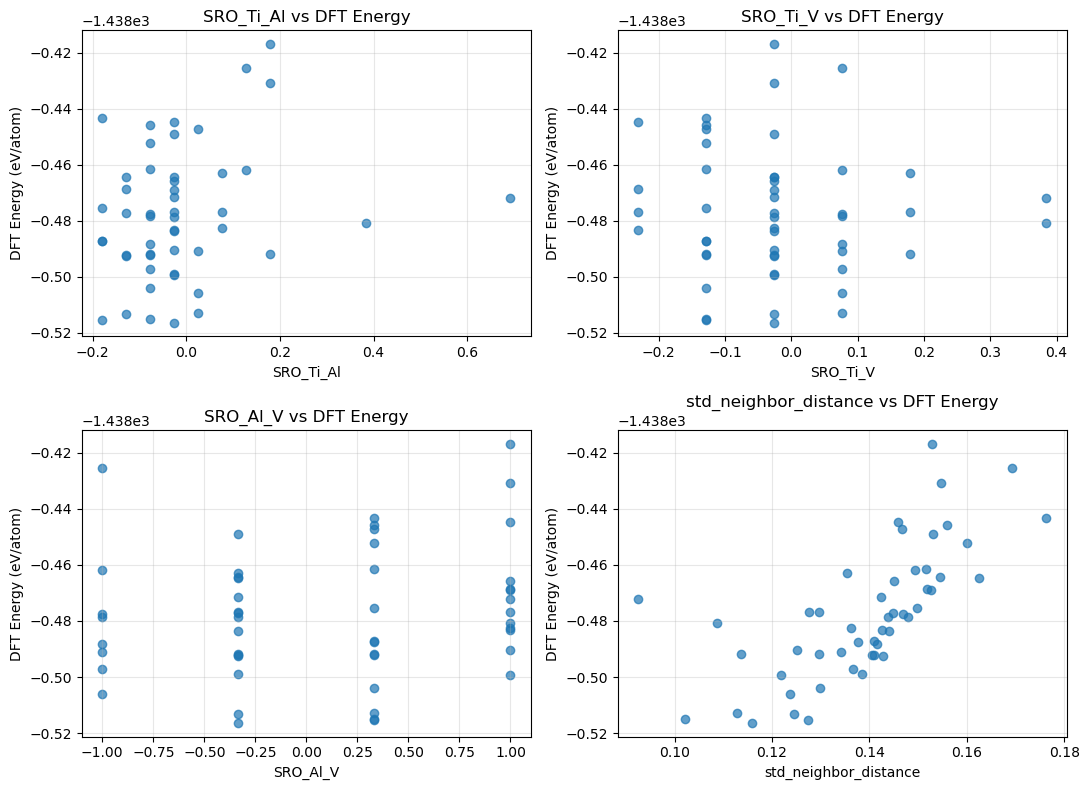

In [31]:
features = [
    "SRO_Ti_Al",
    "SRO_Ti_V",
    "SRO_Al_V",
    "std_neighbor_distance"
]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, feature in zip(axes.flat, features):

    ax.scatter(
        df_hw4[feature],
        df_hw4["DFT_energy_per_atom"],
        alpha=0.7
    )

    ax.set_xlabel(feature)
    ax.set_ylabel("DFT Energy (eV/atom)")
    ax.set_title(f"{feature} vs DFT Energy")

    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [32]:
# Calculate energy relative to the lowest-energy structure
E_min = df_hw4["DFT_energy_per_atom"].min()

df_hw4["delta_E_meV_atom"] = (
    df_hw4["DFT_energy_per_atom"] - E_min
) * 1000

print("Minimum relative energy:",
      df_hw4["delta_E_meV_atom"].min(), "meV/atom")

print("Maximum relative energy:",
      df_hw4["delta_E_meV_atom"].max(), "meV/atom")

display(
    df_hw4[
        ["structure_id", "SRO_Ti_Al",
         "SRO_Al_V", "std_neighbor_distance",
         "delta_E_meV_atom"]
    ].head()
)

Minimum relative energy: 0.0 meV/atom
Maximum relative energy: 99.31115375002264 meV/atom


,structure_id,SRO_Ti_Al,SRO_Al_V,std_neighbor_distance,delta_E_meV_atom
0,3623,-0.025641,1.000000,0.144956,50.539971
1,3672,-0.025641,1.000000,0.127658,39.492837
2,3673,-0.025641,1.000000,0.145872,71.688222
3,3675,-0.076923,-1.000000,0.146913,38.826125
4,3719,-0.179487,0.333333,0.127323,0.785262


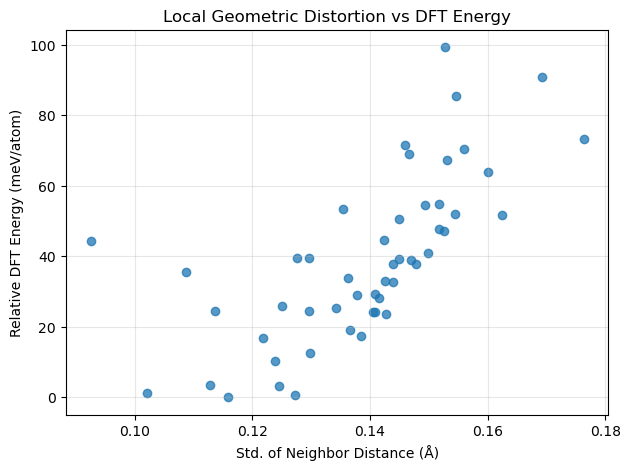

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(
    df_hw4["std_neighbor_distance"],
    df_hw4["delta_E_meV_atom"],
    alpha=0.75
)

plt.xlabel("Std. of Neighbor Distance (Å)")
plt.ylabel("Relative DFT Energy (meV/atom)")
plt.title("Local Geometric Distortion vs DFT Energy")
plt.grid(alpha=0.3)

plt.show()

In [34]:
from pathlib import Path

# Create folders for data organization
PROJECT = Path.cwd()

(PROJECT / "raw").mkdir(exist_ok=True)
(PROJECT / "processed").mkdir(exist_ok=True)
(PROJECT / "scripts").mkdir(exist_ok=True)

# Save processed dataset
output_path = PROJECT / "processed" / "TiAlV_HW1_cleaned.csv"

df_hw4.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("Location:", output_path)
print("Shape:", df_hw4.shape)

Dataset saved successfully!
Location: C:\Users\İpek\Desktop\ML Homeworks\processed\TiAlV_HW1_cleaned.csv
Shape: (50, 16)


The initial dataset consists of 50 HCP-labeled Ti₁₃Al₂V atomic configurations with nearly identical cell volumes. No missing values were found in the selected descriptors. Pearson correlation analysis showed that the standard deviation of nearest-neighbor distances had the strongest positive correlation with DFT energy (r = 0.690), whereas the chemical short-range order descriptors exhibited weaker individual linear correlations. This suggests that local atomic geometry is important for explaining energy variations in the selected perturbed configurations. Further investigation is required to distinguish chemical-ordering effects from atomic displacement effects.

## HW1-4 — Data Curation and Metadata

A metadata file is created to document the original
DFT dataset, the selected atomic configurations,
the units, and the preprocessing methodology.

In [35]:
from pathlib import Path
import json
import hashlib
import shutil

PROJECT = Path.cwd()

raw_folder = PROJECT / "raw"
processed_folder = PROJECT / "processed"
scripts_folder = PROJECT / "scripts"

# Create project folders
for folder in [raw_folder, processed_folder, scripts_folder]:
    folder.mkdir(exist_ok=True)

# Copy the original dataset without modifying it
raw_copy = raw_folder / DATA_PATH.name

if not raw_copy.exists():
    shutil.copy2(DATA_PATH, raw_copy)

# Calculate SHA256 to identify the exact source file
sha256 = hashlib.sha256()

with open(raw_copy, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(chunk)

# Create metadata
metadata = {
    "project_title": "ML Prediction of DFT Configurational Energies in Ti-Al-V",

    "source": {
        "authors": "Allen and Bartok",
        "publication_year": 2025,
        "dataset_url": "https://zenodo.org/records/15114121",
        "original_filename": DATA_PATH.name,
        "sha256": sha256.hexdigest(),
        "data_type": "DFT atomistic configurations"
    },

    "data_selection": {
        "total_source_configurations": len(df_all),
        "selected_configurations": len(df_hw4),
        "composition": "Ti13Al2V",
        "phase_label": "hcp",
        "selection_method": "Same composition and volume group",
        "random_state": 42
    },

    "target": {
        "name": "DFT_energy_per_atom",
        "unit": "eV/atom",
        "description": "DFT total energy divided by number of atoms"
    },

    "descriptors": {
        "SRO_Ti_Al": "dimensionless",
        "SRO_Ti_V": "dimensionless",
        "SRO_Al_V": "dimensionless",
        "mean_neighbor_distance": "Angstrom",
        "std_neighbor_distance": "Angstrom",
        "min_shell_gap": "Angstrom",
        "volume_per_atom": "Angstrom^3/atom"
    },

    "processing_notes": [
        "First 12 nearest neighbors used as local chemical descriptors",
        "Periodic boundary conditions considered",
        "Neighbor search cutoff: 5 Angstrom",
        "Relative energy referenced to minimum energy of selected 50 structures",
        "SRO values are finite-cell descriptors, not converged bulk SRO",
        "Original DFT dataset retained unchanged"
    ],

    "missing_values": int(df_hw4.isna().sum().sum())
}

# Save metadata
metadata_path = PROJECT / "metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)

print("Metadata saved:", metadata_path)
print("Raw dataset copied:", raw_copy)
print("SHA256:", sha256.hexdigest())

Metadata saved: C:\Users\İpek\Desktop\ML Homeworks\metadata.json
Raw dataset copied: C:\Users\İpek\Desktop\ML Homeworks\raw\ti64_combined_data_Apr08.extxyz
SHA256: 85d48a7756c80f0e577056ebc52a16e45fb06b94491feef601587528ee6469cf


### Obstacles and Open Questions

The original Ti-Al-V dataset contains 8,507 DFT atomic configurations belonging to different crystal structure families and chemical compositions. One major challenge was selecting comparable structures for investigating chemical short-range ordering. I selected 50 HCP-labeled Ti13Al2V configurations with nearly identical cell volumes to reduce compositional and volumetric variations. The dataset did not directly provide SRO descriptors, so these were calculated from atomic coordinates using nearest-neighbor analysis under periodic boundary conditions. No missing values were found in the selected dataset. Initial correlation analysis showed a stronger relationship between local geometric distortion and DFT energy than between individual SRO parameters and energy. However, the structures contain atomic perturbations, and the small simulation cells limit the interpretation of SRO. Further analysis is necessary to separate chemical-ordering effects from geometric distortions.

In [36]:
from pathlib import Path

PROJECT = Path.cwd()

# Create a .gitignore file
gitignore = """
.ipynb_checkpoints/
__pycache__/
raw/*.extxyz
"""

(PROJECT / ".gitignore").write_text(
    gitignore.strip() + "\n",
    encoding="utf-8"
)

# Keep the folders visible in Git
(PROJECT / "raw" / ".gitkeep").touch()
(PROJECT / "scripts" / ".gitkeep").touch()

print("Git preparation completed!")
print("Project:", PROJECT)

Git preparation completed!
Project: C:\Users\İpek\Desktop\ML Homeworks
